# Q1.1
It's easy to sample
Choose proposal $q(x)$:
$
q(x) = \mathcal{N}(0, 1) \cdot \mathcal{N}(x_1, 1)
$
$
= \frac{1}{2\pi} \exp\left(-\frac{x_1^2}{2}\right) \exp\left(-\frac{(x_2 - x_1)^2}{2}\right)
$
<br />
$
\mathcal{N}(0,1)
$
for $ x_1 $: Proposes values for $ x_1 $ around 0 with unit variance, which matches the general behavior of the $ x_1 $-dependent term $ -\frac{x_1^2}{10} $ in $ \bar{p}.
$
\
$ \mathcal{N}(x_1,1) $ for $ x_2 $: Proposes values for $ x_2 $ centered around $ x_1 $, which aligns with the coupling $ -2(x_2 - x_1^2)^2 $ in $ \bar{p}.
$


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from scipy.stats import multivariate_normal

def target_density(x1, x2):
    return np.exp(-x1**2 / 10 - x2**2 / 10 - 2 * (x2 - x1**2)**2)

def proposal_density(x1, x2):
    p_x1 = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x1**2)
    p_x2_given_x1 = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * (x2 - x1**2)**2)
    return p_x1 * p_x2_given_x1

x1 = np.random.normal(0, 1)
x2 = np.random.normal(x1 ** 2, 1)

n=50000
m=2*np.exp(32/75)*np.pi
#see calculation below

"
Maximize:
$
M=sup(\frac{\exp\left(-\frac{x^2}{10} - \frac{y^2}{10} - 2(y - x^2)^2\right)}{\frac{1}{2\pi} \exp(-0.5x^2)\exp(-0.5(y-x^2)^2)})
$


$
\max\left\{\frac{\exp\left(-\frac{x^2}{10} - \frac{y^2}{10} - 2(y - x^2)^2\right)}{\frac{1}{2\pi} \exp(-0.5x^2)\exp(-0.5(y-x^2)^2)}\right\} = 2e^{32/75}\pi
$
at:
$
(x, y) = \left(-4\sqrt{\frac{2}{15}}, 2\right)
$
and:
$
(x, y) = \left(4\sqrt{\frac{2}{15}}, 2\right).
$

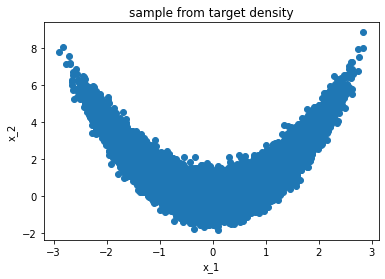

0.34626278575336394
[[-0.27308263 -0.76257908]
 [ 0.49279631 -0.16968786]
 [ 0.99750866  0.64046618]
 ...
 [ 0.74478806  1.01212143]
 [-0.30623138  0.09792678]
 [-0.26599483  0.07501161]]


In [ ]:
n=50000
m=2*np.e**(1/2)*np.pi
def logtarget(x1,x2):
    return -x1**2 / 10 - x2**2 / 10 - 2 * (x2 - x1**2)**2
def rejection_sampler(n,m):
    accept_sample=[]
    number=0
    logm=np.log(m)
    while len(accept_sample)<n:
        x1 = np.random.normal(0, 1)
        x2 = np.random.normal(x1 ** 2, 1)#SAMPLE FROM Q(X)
        logp=logtarget(x1,x2)#PLUG IN LOGP(X)
        logq=-0.5 * x1**2 - np.log(np.sqrt(2 * np.pi))-0.5 * (x2 - x1**2)**2 - np.log(np.sqrt(2 * np.pi))
        v=np.random.uniform(0,1)
        logv=np.log(v)
        if logv<logp-logm-logq:
            accept_sample.append([x1, x2])
        number+=1
    acceptance_rate=len(accept_sample)/number
    return np.array(accept_sample), acceptance_rate

sample,acceptance_rate=rejection_sampler(n,m)
plt.scatter(sample[:,0],sample[:,1])
plt.xlabel("x_1")
plt.ylabel("x_2")
plt.title("sample from target density")
plt.show()

a=rejection_sampler(n,m)[1]
print(a)
print(sample)

In [ ]:
from scipy import integrate
Z,e=integrate.dblquad(target_density,-12,12,-12,12)
print(Z)

3.6013257789914386


In [ ]:

a=Z/m
print(a)
#theoretical accept rate is similar to pratical one

0.34764445003330513


In [ ]:
bananasample = np.load('/Users/cbq/Downloads/samples_.npy')
from scipy.stats import ks_2samp
import numpy as np
x1_samples = sample[:, 0]
x2_samples = sample[:, 1]
x1_banana = bananasample[:, 0]
x2_banana = bananasample[:, 1]
ks_x1 = ks_2samp(x1_samples, x1_banana)
ks_x2 = ks_2samp(x2_samples, x2_banana)
print("p-value for x1 =", ks_x1.pvalue)
print("p-value for x2 =", ks_x2.pvalue)
if ks_x1.pvalue > 0.05 and ks_x2.pvalue > 0.05:
    print("The distributions of x1 and x2 are consistent with the banana samples (p > 0.05).")
else:
    print("There is a significant difference in the distributions (p <= 0.05).")

p-value for x1 = 0.997544854761507
p-value for x2 = 0.5372107095965472
The distributions of x1 and x2 are consistent with the banana samples (p > 0.05).


#question 2.1
By Equation of Marginal Likelihood, we have $p(y_{1:T}) = \int p(y_{1:T}| x) p(x) \, dx$, where the normalised $p(x) = \frac{\bar{p}(x)}{\int \bar{p}(x) \, dx}$.

Thus: $p(y_{1:T}) = \frac{\int p(y_{1:T} | x) \bar{p}(x) \frac{\bar{p}(x)}{q(x)} \, dx}{\int \frac{\bar{p}(x)}{q(x)} q(x) \, dx}$

Simplifying further: $p(y_{1:T}) = \frac{\int p(y_{1:T}| x) w(x_i) q^N(x) \, dx}{\int w(x) q^N(x) \, dx}$, where $w(x) = \frac{\bar{p}(x)}{q(x)} $.

By conditional independence, We have $p(y_{1:T}| x) = \prod_{t=1}^T p(y_t | x)$.

Thus $p(y_{1:T}) = \frac{\frac{1}{N} \sum_{i=1}^N \prod_{t=1}^T p(y_t | x) W(x_i)}{\frac{1}{N} \sum_{i=1}^N W(x_i)} = \frac{\sum_{i=1}^N \prod_{t=1}^T p(y_t | x) W(x_i)}{\sum_{i=1}^N W(x_i)}$, where $W(x_i) = \frac{\bar{p}(x_i)}{q(x_i)}$.


Thus, we have $\sum_{i=1}^N \prod_{t=1}^T p_1(y_t | x) \bar{w_i} = \sum_{i=1}^N \prod_{t=1}^T \mathcal{N}(y_t; Hx, \sigma^2) \bar{w_i}$ as the SNIS estimator of $p_1(y_{1:T})$, where $\bar{w_i} = \frac{W(x_i)}{\sum_{i=1}^N W(x_i)}$.

Similarly, $\sum_{i=1}^N \prod_{t=1}^T p_2(y_t | x) \bar{w_i} = \sum_{i=1}^N \prod_{t=1}^T \text{St}(y_t; Hx, \sigma^2, \nu) \bar{w_i}$ is the SNIS estimator of $p^\nu_2(y_{1:T})$, where $\bar{w_i} = \frac{W(x_i)}{\sum_{i=1}^N W(x_i)}$.

#Quetion 2.2
Let ${W}_i = \exp(\tilde{x}_i)$.

$\bar{w_i} = \frac{\exp(\tilde{x}_i)}{\sum_{i=1}^N \exp(\tilde{x}_i)}$

Use the max trick in lecture notes, we have $\log \tilde{W}_i = {x}_i-\max x_i$.

$ \bar{w_i} = \frac{\exp(\log \tilde{W}_i)}{\sum_{i=1}^N \exp(\log \tilde{W}_i)}=\frac{\exp(x_i - \max x_i)}{\sum_{i=1}^N \exp(x_i - \max x_i)}$


take log of $\bar{w}_i$, $x_i - \log \sum_{i=1}^N \exp(x_i) = x_i - \max(x_i) - \log \sum_{i=1}^N \exp(x_i - \max x_i)$.

We finally achieve: $\log \sum_{i=1}^N \exp(x_i) = \max(x_i) + \log \sum_{i=1}^N \exp(x_i - \max x_i)$.

In [ ]:
def logsumexp(x):
    result=0
    for i in x:
        result+=np.exp(i)
    return np.log(result)
def modified_logsumexp(x):
    result=0
    for i in x:
        result+=np.exp(i-max(x))
    return np.log(result)+max(x)
logsumexp([1,2,3])
modified_logsumexp([1,2,3])

3.4076059644443806

In [ ]:
#Question 2.3
from scipy.special import gamma
def log_SNIS_estimator_Gaussian(n,y,sigma2,H,sample=sample):
    logwlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]#sample from proposal
        logp=logtarget(x1,x2)
        logq=-0.5 * x1**2 - np.log(np.sqrt(2 * np.pi))-0.5 * (x2 - x1**2)**2 - np.log(np.sqrt(2 * np.pi))
        logw=logp-logq
        logwlist.append(logw)
    logsum_w=modified_logsumexp(logwlist)
    logwbar_list=[i-logsum_w for i in logwlist]
    answerlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]
        x=np.array([x1,x2])
        log_likelihood=0
        for element in y:
            likelihood=(1 / (np.sqrt(2 * np.pi * sigma2))) * np.exp(-((element - np.dot(H, x)) ** 2) / (2 * sigma2))
            likelihood = max(likelihood, 1e-10)
            log_likelihood+=np.log(likelihood)
        logwbar=logwbar_list[i]
        sum=logwbar+log_likelihood
        answerlist.append(sum)
    log_of_SNIS_Gaussian=modified_logsumexp(answerlist)
    return log_of_SNIS_Gaussian
#student distribution when nu=2
def log_SNIS_estimator_Student(n,y,sigma2,H,nu=2,sample=sample):
    logwlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]#sample from proposal
        logp=logtarget(x1,x2)
        logq=-0.5 * x1**2 - np.log(np.sqrt(2 * np.pi))-0.5 * (x2 - x1**2)**2 - np.log(np.sqrt(2 * np.pi))
        logw=logp-logq
        logwlist.append(logw)
    logsum_w=modified_logsumexp(logwlist)
    logwbar_list=[i-logsum_w for i in logwlist]
    answerlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]
        x=np.array([x1,x2])
        log_likelihood=0
        for element in y:
            likelihood=(gamma((1+nu) / 2))/ (gamma(nu/2) * np.sqrt(nu * np.pi * sigma2))*(1 + ((element - np.dot(H, x)) ** 2) / (nu * sigma2)) ** (-(nu+1) / 2)
            log_likelihood+=np.log(likelihood)
        logwbar=logwbar_list[i]
        sum=logwbar+log_likelihood
        answerlist.append(sum)
    log_of_SNIS_student=modified_logsumexp(answerlist)
    return log_of_SNIS_student
#naive logsumexp used in Gaussain
def log_SNIS_estimator_Gaussian_naive(n,y,sigma2,H,sample=sample):
    logwlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]#sample from proposal
        logp=logtarget(x1,x2)
        logq=-0.5 * x1**2 - np.log(np.sqrt(2 * np.pi))-0.5 * (x2 - x1**2)**2 - np.log(np.sqrt(2 * np.pi))
        logw=logp-logq
        logwlist.append(logw)
    logsum_w=logsumexp(logwlist)
    logwbar_list=[i-logsum_w for i in logwlist]
    answerlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]
        x=np.array([x1,x2])
        log_likelihood=0
        for element in y:
            likelihood=(1 / (np.sqrt(2 * np.pi * sigma2))) * np.exp(-((element - np.dot(H, x)) ** 2) / (2 * sigma2))
            likelihood = max(likelihood, 1e-10)
            log_likelihood+=np.log(likelihood)
        logwbar=logwbar_list[i]
        sum=logwbar+log_likelihood
        answerlist.append(sum)
    log_of_SNIS_Gaussian=logsumexp(answerlist)
    return log_of_SNIS_Gaussian
#naive logsumexp used in student distribution when nu=2
def log_SNIS_estimator_Student_naive(n,y,sigma2,H,nu=2,sample=sample):
    logwlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]#sample from proposal
        logp=logtarget(x1,x2)
        logq=-0.5 * x1**2 - np.log(np.sqrt(2 * np.pi))-0.5 * (x2 - x1**2)**2 - np.log(np.sqrt(2 * np.pi))
        logw=logp-logq
        logwlist.append(logw)
    logsum_w=logsumexp(logwlist)
    logwbar_list=[i-logsum_w for i in logwlist]
    answerlist=[]
    for i in range(n):
        x1 = sample[i,0]
        x2 = sample[i,1]
        x=np.array([x1,x2])
        log_likelihood=0
        for element in y:
            likelihood=(gamma((1+nu) / 2))/ (gamma(nu/2) * np.sqrt(nu * np.pi * sigma2))*(1 + ((element - np.dot(H, x)) ** 2) / (nu * sigma2)) ** (-(nu+1) / 2)
            log_likelihood+=np.log(likelihood)
        logwbar=logwbar_list[i]
        sum=logwbar+log_likelihood
        answerlist.append(sum)
    log_of_SNIS_student=logsumexp(answerlist)
    return log_of_SNIS_student
H=np.array([0,1])
y= np.load('/Users/cbq/Downloads/y.npy')
sigma2=0.1
print(log_SNIS_estimator_Gaussian(n=100,y=y,sigma2=0.1,H=np.array([0,1])))
print(log_SNIS_estimator_Student(n=100,y=y,sigma2=0.1,H=np.array([0,1])))
print(log_SNIS_estimator_Gaussian_naive(n=100,y=y,sigma2=0.1,H=np.array([0,1])))
print(log_SNIS_estimator_Student_naive(n=100,y=y,sigma2=0.1,H=np.array([0,1])))
#conclusion:the first two function used modified logsumexp gives us the answers of log estimator while the last two used naive logsumexp give us -inf due to number explosion.

-12272.000776185418
-7137.916555582205


/var/folders/c1/gctr2p2503s1yq8n3gn7zg780000gn/T/ipykernel_6772/2583530679.py:5: RuntimeWarning: divide by zero encountered in log
  return np.log(result)


-inf
-inf


In [ ]:
#question 2.4
H=np.array([0,1])
sigma2=0.1
import time
gaussian=[]
for i in range(100):
    np.random.seed(int(time.time()))
    sample = rejection_sampler(500,m)[0]
    phi_SNIS=log_SNIS_estimator_Gaussian(100,y,sigma2,H,sample=sample)
    gaussian.append(phi_SNIS)
    if i % 10 == 0:
        print(f"{i+10}/100 ready.")
gaussian=np.array(gaussian).T

10/100 ready.
20/100 ready.
30/100 ready.
40/100 ready.
50/100 ready.
60/100 ready.
70/100 ready.
80/100 ready.
90/100 ready.
100/100 ready.


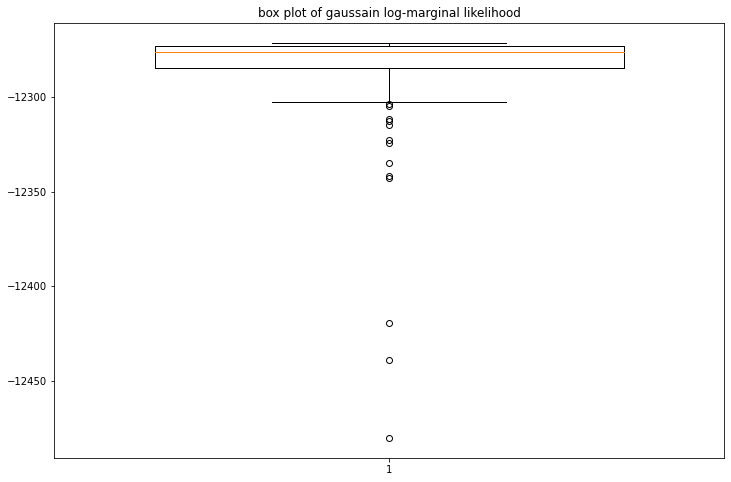

In [ ]:
plt.figure(figsize=(12,8))
plt.boxplot(gaussian,widths=0.7)
plt.title("box plot of gaussain log-marginal likelihood")
plt.show()

In [ ]:
student=[[] for _ in range(100)]
nu_value=np.linspace(1.5,6.5,6)
for i in range(100):
    np.random.seed(int(time.time()))
    sample = rejection_sampler(500,m)[0]
    for nu in nu_value:
        phi_SNIS=log_SNIS_estimator_Student(100,y,sigma2,H,nu=nu,sample=sample)
        student[i].append(phi_SNIS)
    if i % 5 == 0:
        print(f"{i+5}/100 ready.{student[i]}")

5/100 ready.[-7338.9885628634065, -7103.076961933519, -7233.061084101638, -7453.072423237083, -7693.309930889197, -7931.475105262623]
10/100 ready.[-7343.166765441793, -7107.42046937541, -7237.5368337189, -7457.655299153171, -7697.983716024926, -7936.229295131748]
15/100 ready.[-7342.041700729434, -7106.231996085886, -7236.313579327057, -7456.4085686198205, -7696.716261211132, -7934.9400319691385]
20/100 ready.[-7346.84223270399, -7111.3153516928205, -7241.664276158349, -7461.991531067934, -7702.498380838087, -7940.893071942869]
25/100 ready.[-7340.849142942232, -7104.9796829560555, -7235.006517555941, -7455.05574949864, -7695.325684462452, -7933.518217180266]
30/100 ready.[-7390.9217007751495, -7157.43057001556, -7289.545561645581, -7511.353550612902, -7753.120868355141, -7992.610247087921]
35/100 ready.[-7349.447807598321, -7114.040125104166, -7244.48387258258, -7464.886473547603, -7705.4561343310415, -7943.9060461507015]
40/100 ready.[-7339.827337115832, -7103.963367286196, -7233.99

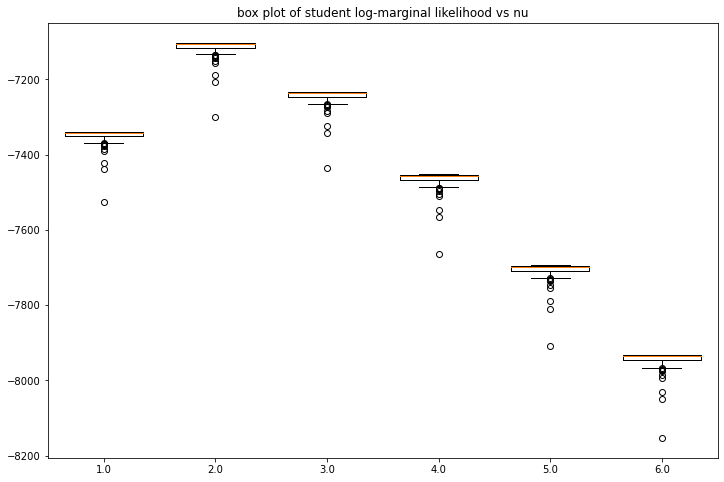

In [ ]:
plt.figure(figsize=(12,8))
plt.boxplot(np.array(student),widths=0.7,labels=[f"{nu:.1f}"for nu in nu_values])
plt.title("box plot of student log-marginal likelihood vs nu")
plt.show()